# Khắc phục LSTM dừng ở epoch 1–2 và giảm phương sai theo seed

**Vấn đề:**
- 75% fold dừng ở epoch 1–2, tức chỉ khoảng 60–120 bước gradient (lr 1e-3, batch 512).
- Log-loss trên tập es chỉ tốt hơn đoán theo tỉ lệ lớp 0.3–6.6%.
- Tương quan giữa các seed là 0.82, so với 0.99 của XGB.
- Model bị dừng giữa chừng trên đường tối ưu, nên kết quả phụ thuộc vào khởi tạo.

**Biến thể** (siêu tham số mới trong `nn_models.LSTMParams`, mặc định là tắt):
| bản | thay đổi | ý tưởng |
|---|---|---|
| gốc | lr 1e-3, đo es mỗi epoch | |
| lr thấp | lr 1e-4, đo es 4 lần / epoch, patience 6 epoch | bước nhỏ, dừng sớm mịn hơn, đi xa hơn trước khi overfit |
| cosine + EMA | lr 3e-4, warmup + cosine, EMA trọng số 0.999, đo 4 lần / epoch | EMA lấy trung bình trên quỹ đạo tối ưu: điểm dừng ổn định hơn, ít phụ thuộc seed |
| cosine + EMA + điều chuẩn | như trên + label smoothing 0.1, nhiễu Gauss 0.1, dropout feature 0.1, weight decay 1e-2 | nhãn tài chính nhiễu: giảm tự tin quá mức, chống học thuộc |
| bag 3 | gốc, 3 model / seed (khác khởi tạo), lấy TB | **tăng số seed**: giảm phương sai trực tiếp (5 seed × 3 = 15 LSTM) |

**Giai đoạn 1 (nhanh, chỉ dev):**
- Chạy 4 quý dev, seed 1000, cho mọi biến thể.
- Đo epoch tốt nhất, mức es tốt hơn đoán theo tỉ lệ lớp, log-loss và AUC của quý test (thuộc dev), và đường học.
- Chọn **một** biến thể huấn luyện (không tính bag) theo dev.

**Giai đoạn 2 (walk-forward đầy đủ, 5 seed, dev + test):**
- So 4 bản: gốc (cache), bag 3, biến thể giai đoạn 1 chọn, và biến thể đó + bag 3.
- Mỗi bản dùng riêng và gộp 50/50 với XGB, giữ tham số giao dịch đã khoá.
- Đo độ đồng thuận seed (tương quan, Jaccard top 10%) và TB / std / seed tệ nhất.

**Đổi production khi:** bản gộp có TB seed test tăng VÀ dải seed hẹp lại, đồng thời dev không kém hơn.

**Thời gian:** giai đoạn 1 khoảng 20–40 phút. Giai đoạn 2 khoảng 2–3 giờ cho mỗi bản mới trên GPU; có cache, nên dừng giữa chừng rồi chạy lại vẫn tiếp tục được. Kết quả lưu ở `artifacts/1h_strategy_v2/exp_lstm_training/`.

In [1]:
import os, sys
from dataclasses import replace
from itertools import combinations
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "model_training").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "model_training"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import strategy_h1 as st
import nn_models as nm

pd.set_option("display.width", 240, "display.max_columns", 50)
cfg = st.load_locked("artifacts/1h_strategy_v2/config_locked.json")
XG, LS = replace(cfg, model_kind="xgb"), replace(cfg, model_kind="lstm", nn_params={})
OUT = Path(cfg.output_dir) / "exp_lstm_training"
OUT.mkdir(parents=True, exist_ok=True)
D = st.build(cfg)
y3 = st.direction_labels(D.ds)
lab = D.ds.labels
touched, up_first = (lab["y_touch"] == 1) & (lab["first"] != 0), lab["first"] == 1

TRAIN_VARIANTS = {
    "gốc": {},
    "lr thấp": {"lr": 1e-4, "eval_per_epoch": 4, "patience": 6},
    "cosine + EMA": {"lr": 3e-4, "lr_schedule": "cosine", "max_epochs": 30, "ema": 0.999, "eval_per_epoch": 4, "patience": 6},
    "cosine + EMA + điều chuẩn": {"lr": 3e-4, "lr_schedule": "cosine", "max_epochs": 30, "ema": 0.999, "eval_per_epoch": 4,
                                  "patience": 6, "label_smoothing": 0.1, "input_noise": 0.1, "input_dropout": 0.1,
                                  "weight_decay": 1e-2},
}
BAG = {"n_models": 3}

Dữ liệu: 54,979 nến 1h, 53,522 mẫu (2020-08-30 -> 2026-10-08), touch 92 feature, direction 37 feature, 39s


## Giai đoạn 1: 4 quý dev, seed 1000

In [2]:
DIAG_Q = ["2022Q4", "2023Q3", "2024Q2", "2024Q4"]

def ll3(pr, idx):
    return float(-np.mean(np.log(np.clip(pr[np.arange(len(idx)), y3[idx]], 1e-7, 1))))

def auc_dir(pr, idx):
    ok = touched[idx]
    return float(roc_auc_score(up_first[idx][ok], (0.5 + 0.5 * (pr[:, 1] - pr[:, 2]))[ok])) if ok.sum() > 50 else np.nan

rows, CURVES = [], {}
for q in DIAG_Q:
    sp = st.fold_split(D, pd.Period(q, "Q"), cfg)
    prior = np.bincount(y3[sp["train"]], minlength=3) / len(sp["train"])
    base_ll = float(-np.mean(np.log(prior[y3[sp["es"]]])))
    for name, over in {**TRAIN_VARIANTS, "bag 3": BAG}.items():
        m = nm.fit_direction_nn(D, sp, replace(LS, nn_params=over), 1000)
        one = m.members[0] if isinstance(m, nm.Bag) else m
        CURVES[(q, name)] = (one.train_history, one.history, nm.make_params("lstm", over).eval_per_epoch)
        pt = m.predict_proba(sp["test"])
        rows.append({"quý": q, "bản": name, "epoch tốt nhất": m.best_epoch,
                     "es tốt hơn đoán theo tỉ lệ lớp %": (base_ll - m.best_logloss) / base_ll * 100,
                     "log-loss quý test": ll3(pt, sp["test"]), "AUC quý test": auc_dir(pt, sp["test"]),
                     "AUC train": auc_dir(m.predict_proba(sp["train"]), sp["train"])})
        print(q, name, "epoch", round(m.best_epoch, 2))
S1 = pd.DataFrame(rows)
S1.to_csv(OUT / "stage1_dev.csv", index=False)
S1g = S1.groupby("bản", sort=False)[["epoch tốt nhất", "es tốt hơn đoán theo tỉ lệ lớp %", "log-loss quý test", "AUC quý test", "AUC train"]].mean()
S1g["AUC train − test"] = S1g["AUC train"] - S1g["AUC quý test"]
S1g.round(4)

2022Q4 gốc epoch 4
2022Q4 lr thấp epoch 17.25


c:\Users\thanh\BTC_PIPELINE\.venv\lib\site-packages\torch\nn\modules\rnn.py:1123: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1410.)
  result = _VF.lstm(


2022Q4 cosine + EMA epoch 30.0


c:\Users\thanh\BTC_PIPELINE\.venv\lib\site-packages\torch\nn\modules\rnn.py:1123: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1410.)
  result = _VF.lstm(


2022Q4 cosine + EMA + điều chuẩn epoch 30.0
2022Q4 bag 3 epoch 3.67
2023Q3 gốc epoch 3
2023Q3 lr thấp epoch 10.5


c:\Users\thanh\BTC_PIPELINE\.venv\lib\site-packages\torch\nn\modules\rnn.py:1123: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1410.)
  result = _VF.lstm(


... (8 outputs left out)

2024Q4 cosine + EMA epoch 26.0


c:\Users\thanh\BTC_PIPELINE\.venv\lib\site-packages\torch\nn\modules\rnn.py:1123: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1410.)
  result = _VF.lstm(


2024Q4 cosine + EMA + điều chuẩn epoch 29.25
2024Q4 bag 3 epoch 2.67


,epoch tốt nhất,es tốt hơn đoán theo tỉ lệ lớp %,log-loss quý test,AUC quý test,AUC train,AUC train − test
bản,,,,,,
gốc,3.2500,3.0277,0.9601,0.5762,0.6477,0.0715
lr thấp,13.2500,2.9313,0.9609,0.5805,0.6219,0.0414
cosine + EMA,29.0000,0.6696,0.9986,0.5701,0.6581,0.0879
cosine + EMA + điều chuẩn,29.8125,0.4730,1.0031,0.5715,0.6581,0.0866
bag 3,2.8333,3.4423,0.9449,0.5921,0.6480,0.0559


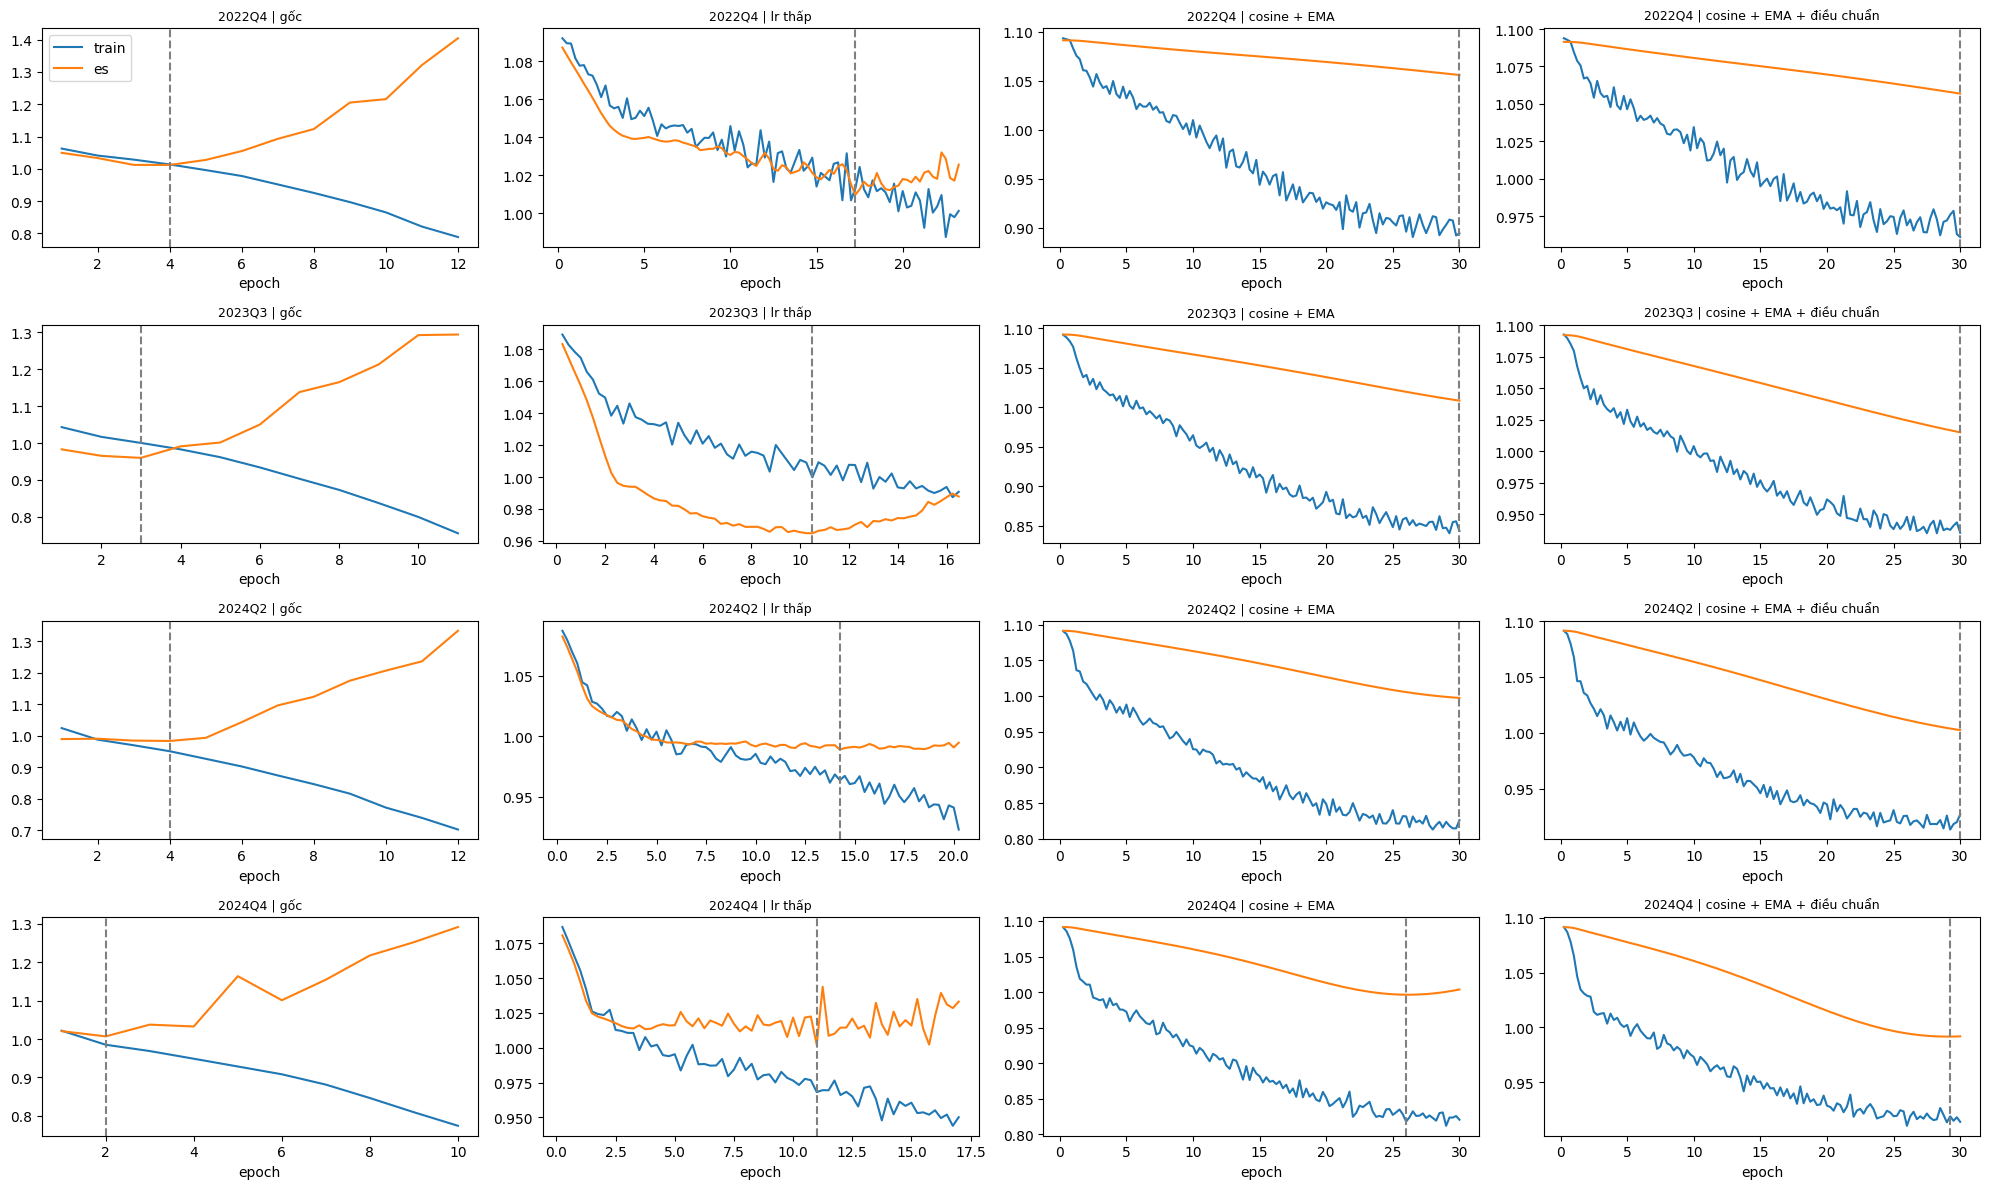

In [3]:
fig, axes = plt.subplots(len(DIAG_Q), len(TRAIN_VARIANTS), figsize=(20, 3 * len(DIAG_Q)), squeeze=False)
for r, q in enumerate(DIAG_Q):
    for c, name in enumerate(TRAIN_VARIANTS):
        tr_h, es_h, ne = CURVES[(q, name)]
        x = np.arange(1, len(es_h) + 1) / ne
        ax = axes[r, c]
        ax.plot(x, tr_h, label="train"); ax.plot(x, es_h, label="es")
        ax.axvline(x[int(np.argmin(es_h))], color="grey", ls="--")
        ax.set_title(f"{q} | {name}", fontsize=9); ax.set_xlabel("epoch")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

In [4]:
# chọn 1 biến thể huấn luyện (khác 'gốc') theo dev: log-loss quý test thấp nhất, rồi AUC
cand = S1g.drop(index=["gốc", "bag 3"])
PICK = cand.sort_values(["log-loss quý test", "AUC quý test"], ascending=[True, False]).index[0]
print("giai đoạn 1 chọn:", PICK, TRAIN_VARIANTS[PICK])

giai đoạn 1 chọn: lr thấp {'lr': 0.0001, 'eval_per_epoch': 4, 'patience': 6}


## Giai đoạn 2: walk-forward đầy đủ, 5 seed, dev + test

In [5]:
STAGE2 = {"gốc": {}, "bag 3": BAG, PICK: TRAIN_VARIANTS[PICK], f"{PICK} + bag 3": {**TRAIN_VARIANTS[PICK], **BAG}}
PX = {ph: st.walk_forward(D, XG, ph)[0] for ph in ("dev", "test")}                       # cache
P2 = {}
for name, over in STAGE2.items():
    for ph in ("dev", "test"):
        if not over:
            Pl = st.blend_direction({"xgb": PX[ph], "lstm": st.walk_forward(D, LS, ph)[0]}, {"lstm": 1.0})   # cache
        else:
            Pl = st.walk_forward_direction(D, replace(LS, nn_params=over), PX[ph], ph)
        P2[(name, ph)] = Pl

dev 2022Q1: AUC touch 0.610 | AUC direction 0.616 | train 7,303 | 0s
dev 2022Q2: AUC touch 0.695 | AUC direction 0.536 | train 9,511 | 0s
dev 2022Q3: AUC touch 0.605 | AUC direction 0.520 | train 11,719 | 0s
dev 2022Q4: AUC touch 0.689 | AUC direction 0.601 | train 13,879 | 0s
dev 2023Q1: AUC touch 0.664 | AUC direction 0.675 | train 16,063 | 0s
dev 2023Q2: AUC touch 0.692 | AUC direction 0.588 | train 18,271 | 0s
dev 2023Q3: AUC touch 0.751 | AUC direction 0.565 | train 20,479 | 0s
dev 2023Q4: AUC touch 0.721 | AUC direction 0.566 | train 22,639 | 0s
dev 2024Q1: AUC touch 0.718 | AUC direction 0.571 | train 24,823 | 0s
dev 2024Q2: AUC touch 0.749 | AUC direction 0.587 | train 27,031 | 0s
dev 2024Q3: AUC touch 0.735 | AUC direction 0.585 | train 29,239 | 0s
dev 2024Q4: AUC touch 0.778 | AUC direction 0.626 | train 31,423 | 0s
test 2025Q1: AUC touch 0.763 | AUC direction 0.552 | train 33,607 | 0s
test 2025Q2: AUC touch 0.729 | AUC direction 0.556 | train 35,815 | 0s
test 2025Q3: AUC tou

In [6]:
def tail_sets(Pf, col, frac=0.10):
    T = Pf[Pf.is_test]
    d = (T[col] - 0.5).abs()
    thr = d.groupby(T.fold).transform(lambda x: x.quantile(1 - frac))
    return set(T.t_ns[d >= thr])

W = {"xgb": 0.5, "lstm": 0.5}
rows = []
for name in STAGE2:
    for ph in ("dev", "test"):
        Pl = P2[(name, ph)]
        T = Pl[Pl.is_test]
        cols = [f"p_up_s{s}" for s in cfg.seeds]
        C = T[cols].corr(method="spearman").to_numpy()[np.triu_indices(len(cols), 1)]
        sets = [tail_sets(Pl, c) for c in cols]
        jac = [len(a & b) / len(a | b) for a, b in combinations(sets, 2)]
        for how, PP in (("chỉ LSTM", Pl), ("gộp 50/50", st.blend_direction({"xgb": PX[ph], "lstm": Pl}, W))):
            S = st.seed_table(D, PP, cfg, ph)
            rows.append({"bản": name, "Direction": how, "phase": ph,
                         "AUC chạm trước": st.direction_auc(D, PP)["AUC chạm trước (đã chạm)"].mean(),
                         "R ens": S.loc["ens", "R/lệnh"], "TB seed": S.loc["TB seed", "R/lệnh"], "std seed": S.loc["std seed", "R/lệnh"],
                         "seed tệ nhất": S.loc["seed tệ nhất", "R/lệnh"], "tương quan seed LSTM": C.mean(), "Jaccard top 10% LSTM": np.mean(jac)})
S2 = pd.DataFrame(rows)
S2.to_csv(OUT / "stage2_walkforward.csv", index=False)
S2.pivot_table(index=["Direction", "bản"], columns="phase",
               values=["AUC chạm trước", "TB seed", "std seed", "seed tệ nhất", "tương quan seed LSTM", "Jaccard top 10% LSTM"],
               sort=False).round(3)

AUC chạm trước        TB seed        std seed        seed tệ nhất        tương quan seed LSTM        Jaccard top 10% LSTM       
phase                                dev   test     dev   test      dev   test          dev   test                  dev   test                  dev   test
Direction bản                                                                                                                                             
chỉ LSTM  gốc                      0.592  0.563   0.149  0.180    0.042  0.059        0.104  0.112                0.764  0.801                0.399  0.428
          bag 3                    0.594  0.562   0.180  0.173    0.025  0.022        0.140  0.152                0.911  0.893                0.601  0.569
          lr thấp                  0.589  0.560   0.168  0.183    0.038  0.047        0.103  0.132                0.799  0.847                0.410  0.400
          lr thấp + bag 3          0.592  0.559   0.180  0.187    0.023  0.028        0.143  0.158                0.934  0.945                0.605  0.607
gộp 50/50 gốc                      0.596  0.570   0.196  0.194    0.021  0.020        0.176  0.174                0.764  0.801                0.399  0.428
          bag 3                    0.596  0.569   0.209  0.184    0.028  0.019        0.180  0.161                0.911  0.893                0.601  0.569
          lr thấp                  0.595  0.568   0.202  0.198    0.018  0.029        0.181  0.150                0.799  0.847                0.410  0.400
          lr thấp + bag 3          0.596  0.568   0.214  0.183    0.020  0.030        0.190  0.151                0.934  0.945                0.605  0.607

**Đổi production:** nếu một bản trong giai đoạn 2 đạt quy tắc (gộp 50/50: TB seed test tăng, std giảm, seed tệ nhất tăng, dev không kém hơn so với "gốc"), đặt `cfg.nn_params` của Direction LSTM bằng biến thể đó rồi chạy lại `train_strategy_h1.ipynb`.